#Install Dependencies

_(Remember to choose GPU in Runtime if not already selected. Runtime --> Change Runtime Type --> Hardware accelerator --> GPU)_

In [1]:
# clone Scaled_YOLOv4
!git clone https://github.com/roboflow-ai/ScaledYOLOv4.git  # clone repo
%cd /content/ScaledYOLOv4/
#checkout the yolov4-large branch
!git checkout yolov4-large

Cloning into 'ScaledYOLOv4'...
remote: Enumerating objects: 133, done.
remote: Counting objects: 100% (5/5), done.
remote: Compressing objects: 100% (5/5), done.
remote: Total 133 (delta 0), reused 2 (delta 0), pack-reused 128 (from 1)
Receiving objects: 100% (133/133), 409.42 KiB | 27.29 MiB/s, done.
Resolving deltas: 100% (39/39), done.
/content/ScaledYOLOv4
Branch 'yolov4-large' set up to track remote branch 'yolov4-large' from 'origin'.
Switched to a new branch 'yolov4-large'


In [2]:
import torch
print('Using torch %s %s' % (torch.__version__, torch.cuda.get_device_properties(0) if torch.cuda.is_available() else 'CPU'))

Using torch 2.4.1+cu121 _CudaDeviceProperties(name='NVIDIA A100-SXM4-40GB', major=8, minor=0, total_memory=40513MB, multi_processor_count=108)


In [3]:
#install mish activation funciton for cuda
%cd /content/
!git clone https://github.com/JunnYu/mish-cuda
%cd mish-cuda
!python setup.py build install

/content
Cloning into 'mish-cuda'...
remote: Enumerating objects: 195, done.
remote: Counting objects: 100% (26/26), done.
remote: Compressing objects: 100% (6/6), done.
remote: Total 195 (delta 20), reused 20 (delta 20), pack-reused 169 (from 1)
Receiving objects: 100% (195/195), 203.57 KiB | 18.51 MiB/s, done.
Resolving deltas: 100% (64/64), done.
/content/mish-cuda
/usr/local/lib/python3.10/dist-packages/setuptools/_distutils/extension.py:134: UserWarning: Unknown Extension options: 'headers'
  warnings.warn(msg)
running build
running build_py
creating build
creating build/lib.linux-x86_64-cpython-310
creating build/lib.linux-x86_64-cpython-310/mish_cuda
copying src/mish_cuda/__init__.py -> build/lib.linux-x86_64-cpython-310/mish_cuda
running egg_info
creating src/mish_cuda.egg-info
writing src/mish_cuda.egg-info/PKG-INFO
writing dependency_links to src/mish_cuda.egg-info/dependency_links.txt
writing requirements to src/mish_cuda.egg-info/requires.txt
writing top-level names to src/

In [4]:
!pip install -U PyYAML

In [5]:
%cd /content/ScaledYOLOv4/


/content/ScaledYOLOv4


# Download Correctly Formatted Custom Dataset

We'll download our dataset from Roboflow. Use the "**ScaledYOLOV4**" export format. Note that the Ultralytics implementation calls for a YAML file defining where your training and test data is. The Roboflow export also writes this format for us.

To get your data into Roboflow, follow the [Getting Started Guide](https://blog.roboflow.ai/getting-started-with-roboflow/).

In [6]:
!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="VqXTGtNgLyBbmOAQwALc")
project = rf.workspace("fastercnn-uqhjy").project("melanomaaaa-mid")
version = project.version(1)
dataset = version.download("yolov4scaled")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 7.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.8/66.8 kB 6.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.5/54.5 kB 4.9 MB/s eta 0:00:00
  Attempting uninstall: idna
    Found existing installation: idna 3.10
    Uninstalling idna-3.10:
      Successfully uninstalled idna-3.10
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to melanomaaaa-mid-1 in yolov4scaled:: 100%|██████████| 4838/4838 [00:00<00:00, 7443.08it/s]


In [7]:
# this is the YAML file Roboflow wrote for us that we're loading into this notebook with our data
%cat {dataset.location}/data.yaml

train: /content/ScaledYOLOv4/melanomaaaa-mid-1/train/images
val: /content/ScaledYOLOv4/melanomaaaa-mid-1/valid/images
test: /content/ScaledYOLOv4/melanomaaaa-mid-1/test/images

nc: 4
names: ['0', '1', '2', '3']

roboflow:
  workspace: fastercnn-uqhjy
  project: melanomaaaa-mid
  version: 1
  license: CC BY 4.0
  url: https://universe.roboflow.com/fastercnn-uqhjy/melanomaaaa-mid/dataset/1

#Inspect Model Configuration and Architecture

Let's look at the Scaled-YOLOv4 Configuration architecture

In [8]:
%cat /content/ScaledYOLOv4/models/yolov4-csp.yaml

# parameters
nc: 80  # number of classes
depth_multiple: 1.0  # model depth multiple
width_multiple: 1.0  # layer channel multiple

# anchors
anchors:
  - [12,16, 19,36, 40,28]  # P3/8
  - [36,75, 76,55, 72,146]  # P4/16
  - [142,110, 192,243, 459,401]  # P5/32

# yolov4-csp backbone
backbone:
  # [from, number, module, args]
  [[-1, 1, Conv, [32, 3, 1]],  # 0
   [-1, 1, Conv, [64, 3, 2]],  # 1-P1/2
   [-1, 1, Bottleneck, [64]],
   [-1, 1, Conv, [128, 3, 2]],  # 3-P2/4
   [-1, 2, BottleneckCSP, [128]],
   [-1, 1, Conv, [256, 3, 2]],  # 5-P3/8
   [-1, 8, BottleneckCSP, [256]],
   [-1, 1, Conv, [512, 3, 2]],  # 7-P4/16
   [-1, 8, BottleneckCSP, [512]],
   [-1, 1, Conv, [1024, 3, 2]], # 9-P5/32
   [-1, 4, BottleneckCSP, [1024]],  # 10
  ]

# yolov4-csp head
# na = len(anchors[0])
head:
  [[-1, 1, SPPCSP, [512]], # 11
   [-1, 1, Conv, [256, 1, 1]],
   [-1, 1, nn.Upsample, [None, 2, 'nearest']],
   [8, 1, Conv, [256, 1, 1]], # route backbone P4
   [[-1, -2], 1, Concat, [1]],
   [-1, 2, Bott

# Train Custom Scaled-YOLOv4 Detector

### Next, we'll fire off training!


Here, we are able to pass a number of arguments:
- **img:** define input image size
- **batch:** determine batch size
- **epochs:** define the number of training epochs. (Note: often, 3000+ are common here!)
- **data:** set the path to our yaml file
- **cfg:** specify our model configuration
- **weights:** specify a custom path to weights.
- **name:** result names
- **nosave:** only save the final checkpoint
- **cache:** cache images for faster training

In [9]:
orig_dataset_directory = dataset.location
orig_dataset_directory

'/content/ScaledYOLOv4/melanomaaaa-mid-1'

In [10]:
%cd {orig_dataset_directory}
%cp -r {orig_dataset_directory} /content/ScaledYOLOv4

/content/ScaledYOLOv4/melanomaaaa-mid-1
cp: '/content/ScaledYOLOv4/melanomaaaa-mid-1' and '/content/ScaledYOLOv4/melanomaaaa-mid-1' are the same file


In [11]:
import os

# Define the paths to the files
datasets_file = '/content/ScaledYOLOv4/utils/datasets.py'
general_file = '/content/ScaledYOLOv4/utils/general.py'

# Function to replace np.int with int in a file
def replace_np_int(file_path):
    # Read the file content
    with open(file_path, 'r') as file:
        content = file.read()

    # Replace np.int with int
    content = content.replace('(np.int)', '(int)')

    # Write the updated content back to the file
    with open(file_path, 'w') as file:
        file.write(content)

# Replace np.int in the specified files
replace_np_int(datasets_file)
replace_np_int(general_file)

print("Replaced 'np.int' with 'int' in datasets.py and general.py")

Replaced 'np.int' with 'int' in datasets.py and general.py


In [12]:
# train scaled-YOLOv4 on custom data for 100 epochs
# time its performance
%%time
%cd /content/ScaledYOLOv4/
!python train.py --img 416 --batch 16 --epochs 600 --data {dataset.location}/data.yaml --cfg ./models/yolov4-csp.yaml --weights '' --name yolov4-csp-results  --cache

/content/ScaledYOLOv4
2024-09-24 01:22:40.152509: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2024-09-24 01:22:40.170281: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:485] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-09-24 01:22:40.191756: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:8454] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-09-24 01:22:40.198236: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1452] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2024-09-24 01:22:40.213801: I tensorflow/core/pla

In [20]:
!python test.py --weights ./runs/exp0_yolov4-csp-results/weights/best_yolov4-csp-results_strip.pt --data {dataset.location}/data.yaml --batch-size 16 --img-size 416 --conf-thres 0.5 --iou-thres 0.6 --save-json --device 0 --verbose

Namespace(weights=['./runs/exp0_yolov4-csp-results/weights/best_yolov4-csp-results_strip.pt'], data='/content/ScaledYOLOv4/melanomaaaa-mid-1/data.yaml', batch_size=16, img_size=416, conf_thres=0.5, iou_thres=0.6, save_json=True, task='val', device='0', single_cls=False, augment=False, merge=False, verbose=True, save_txt=False)
Using CUDA device0 _CudaDeviceProperties(name='NVIDIA A100-SXM4-40GB', total_memory=40513MB)

/content/ScaledYOLOv4/models/experimental.py:137: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no lo

In [21]:
!python test.py --weights ./runs/exp0_yolov4-csp-results/weights/last_yolov4-csp-results_strip.pt --data {dataset.location}/data.yaml --batch-size 16 --img-size 416 --conf-thres 0.5 --iou-thres 0.6 --save-json --device 0 --verbose

Namespace(weights=['./runs/exp0_yolov4-csp-results/weights/last_yolov4-csp-results_strip.pt'], data='/content/ScaledYOLOv4/melanomaaaa-mid-1/data.yaml', batch_size=16, img_size=416, conf_thres=0.5, iou_thres=0.6, save_json=True, task='val', device='0', single_cls=False, augment=False, merge=False, verbose=True, save_txt=False)
Using CUDA device0 _CudaDeviceProperties(name='NVIDIA A100-SXM4-40GB', total_memory=40513MB)

/content/ScaledYOLOv4/models/experimental.py:137: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no lo

# Evaluate Custom Scaled-YOLOv4 Detector Performance

Training losses and performance metrics are saved to Tensorboard and also to a logfile defined above with the **--name** flag when we train. In our case, we named this `yolov5s_results`. (If given no name, it defaults to `results.txt`.) The results file is plotted as a png after training completes.

Note from Glenn: Partially completed `results.txt` files can be plotted with `from utils.utils import plot_results; plot_results()`.

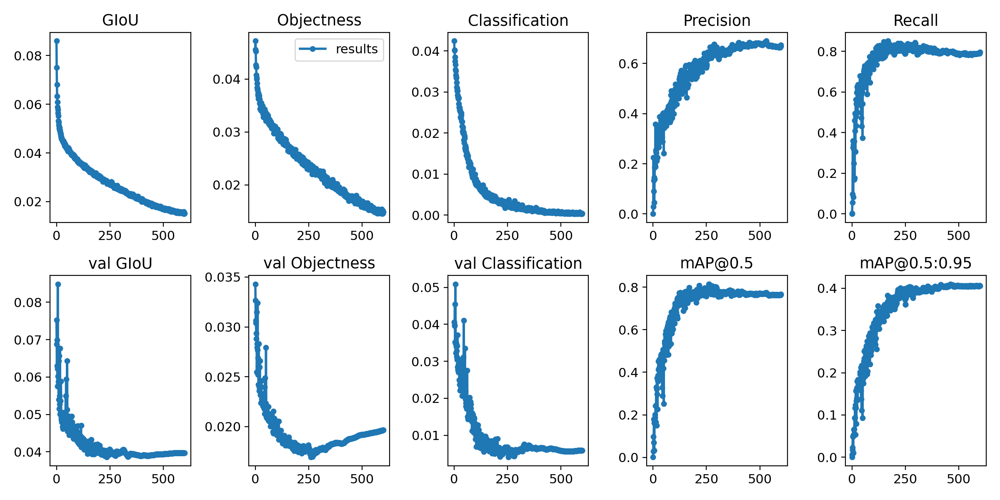

In [13]:
# we can also output some older school graphs if the tensor board isn't working for whatever reason...
#from utils.general import plot_results  # plot results.txt as results.png
from IPython.display import Image, display
display(Image('/content/ScaledYOLOv4/runs/exp0_yolov4-csp-results/results.png'))  # view results.png

### Curious? Visualize Our Training Data with Labels

After training starts, view `train*.jpg` images to see training images, labels and augmentation effects.

Note a mosaic dataloader is used for training (shown below), a new dataloading concept developed by Glenn Jocher and first featured in [YOLOv4](https://arxiv.org/abs/2004.10934).

GROUND TRUTH TRAINING DATA:


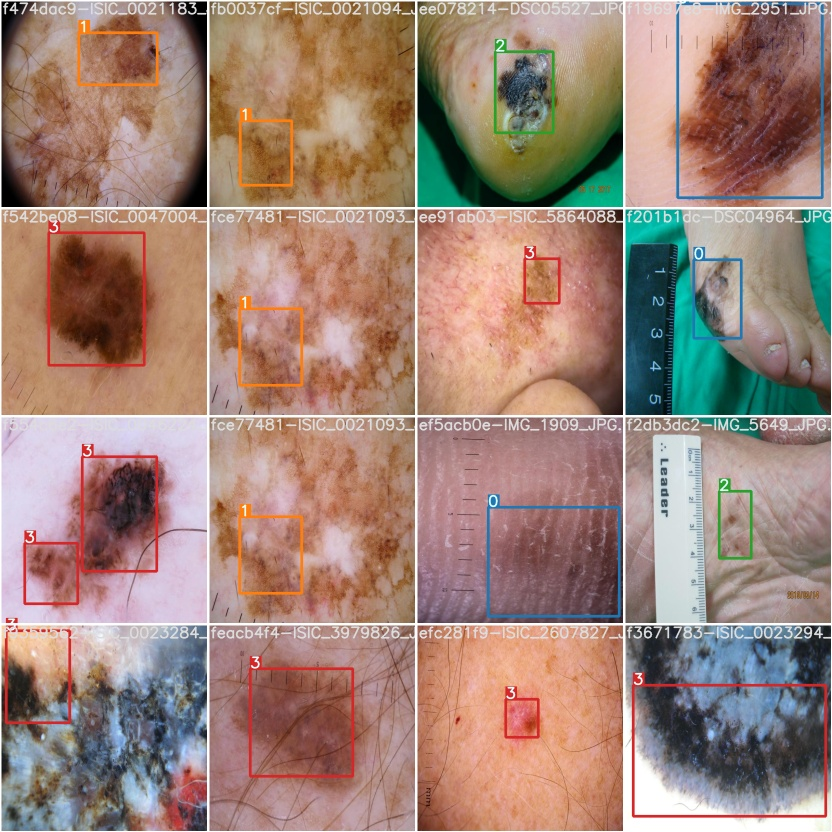

In [14]:
# first, display our ground truth data
print("GROUND TRUTH TRAINING DATA:")
Image(filename='/content/ScaledYOLOv4/runs/exp0_yolov4-csp-results/test_batch0_gt.jpg', width=900)

GROUND TRUTH AUGMENTED TRAINING DATA:


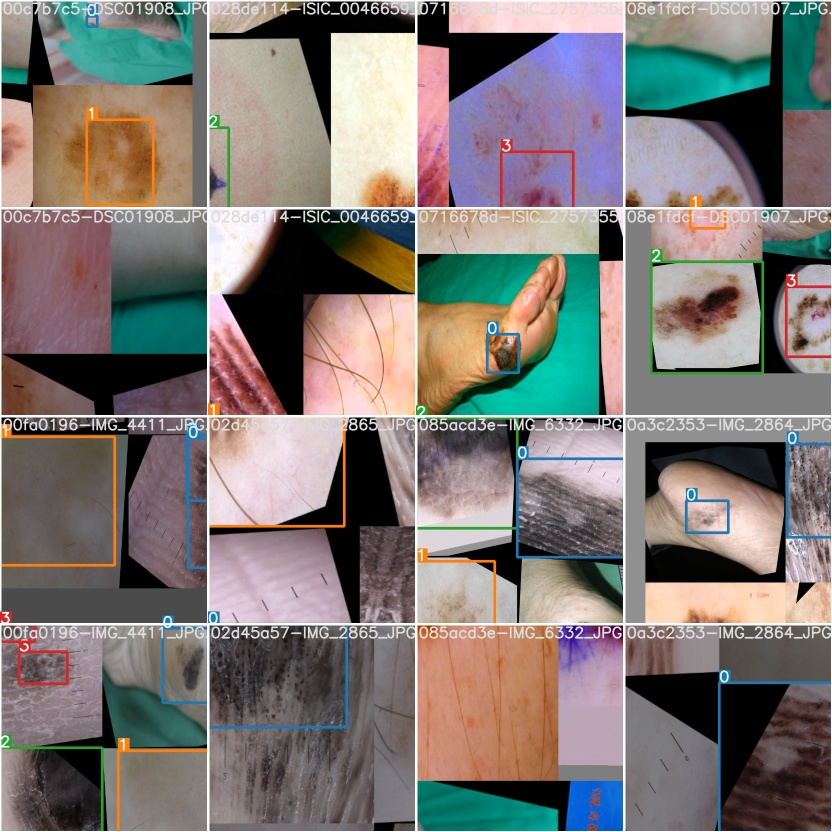

In [15]:
# print out an augmented training example
print("GROUND TRUTH AUGMENTED TRAINING DATA:")
Image(filename='/content/ScaledYOLOv4/runs/exp0_yolov4-csp-results/train_batch0.jpg', width=900)

#Run Inference  With Trained Weights
Run inference with a pretrained checkpoint on contents of `test/images` folder downloaded from Roboflow.

In [16]:
# trained weights are saved by default in our weights folder
%ls runs/

exp0_yolov4-csp-results/


In [17]:
%ls ./runs/exp0_yolov4-csp-results/weights

best_yolov4-csp-results.pt        last_577.pt  last_586.pt  last_595.pt
best_yolov4-csp-results_strip.pt  last_578.pt  last_587.pt  last_596.pt
last_570.pt                       last_579.pt  last_588.pt  last_597.pt
last_571.pt                       last_580.pt  last_589.pt  last_598.pt
last_572.pt                       last_581.pt  last_590.pt  last_599.pt
last_573.pt                       last_582.pt  last_591.pt  last_yolov4-csp-results.pt
last_574.pt                       last_583.pt  last_592.pt  last_yolov4-csp-results_strip.pt
last_575.pt                       last_584.pt  last_593.pt
last_576.pt                       last_585.pt  last_594.pt


Running Inference:

In [18]:
# when we ran this, we saw .007 second inference time. That is 140 FPS on a TESLA P100!
# use the best weights!
%cd /content/ScaledYOLOv4/
TEST_DIR = f'{dataset.location}/test/images'
!python detect.py --weights ./runs/exp0_yolov4-csp-results/weights/best_yolov4-csp-results.pt --img 416 --conf 0.6 --source {TEST_DIR}

/content/ScaledYOLOv4
Namespace(weights=['./runs/exp0_yolov4-csp-results/weights/best_yolov4-csp-results.pt'], source='/content/ScaledYOLOv4/melanomaaaa-mid-1/test/images', output='inference/output', img_size=416, conf_thres=0.6, iou_thres=0.5, device='', view_img=False, save_txt=False, classes=None, agnostic_nms=False, augment=False, update=False)
Using CUDA device0 _CudaDeviceProperties(name='NVIDIA A100-SXM4-40GB', total_memory=40513MB)

/content/ScaledYOLOv4/models/experimental.py:137: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitr

/content/ScaledYOLOv4


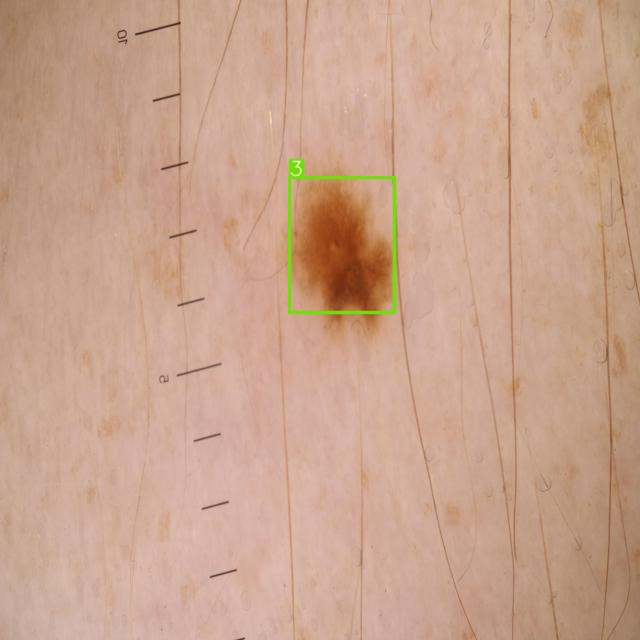

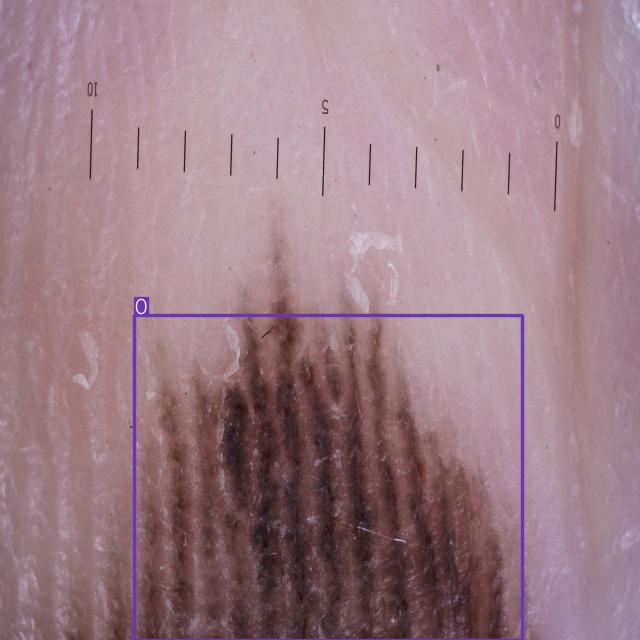

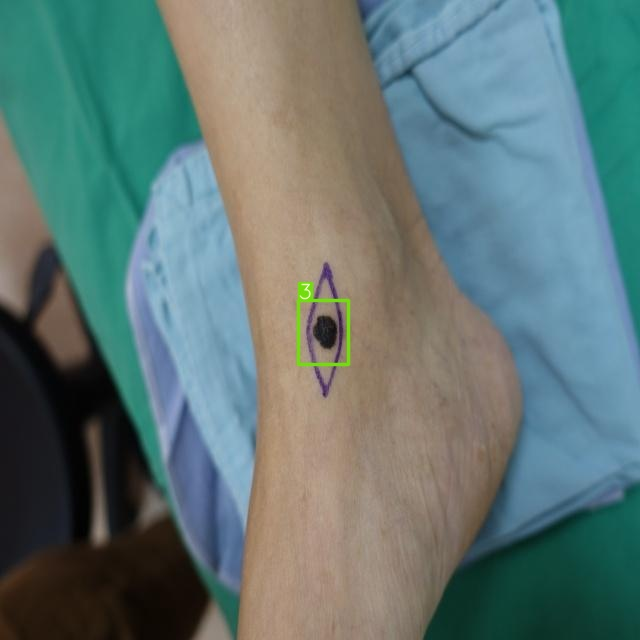

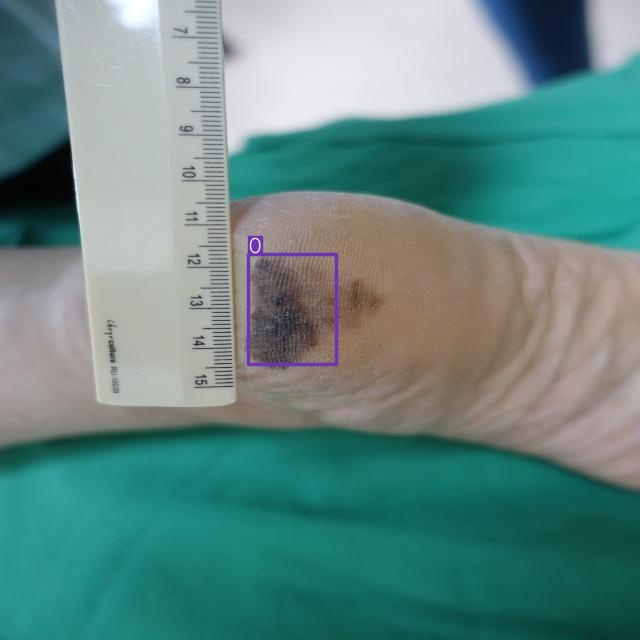

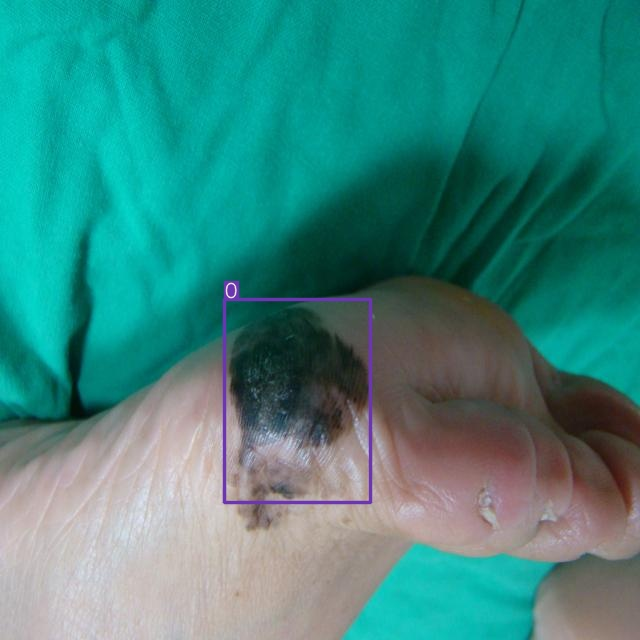

...

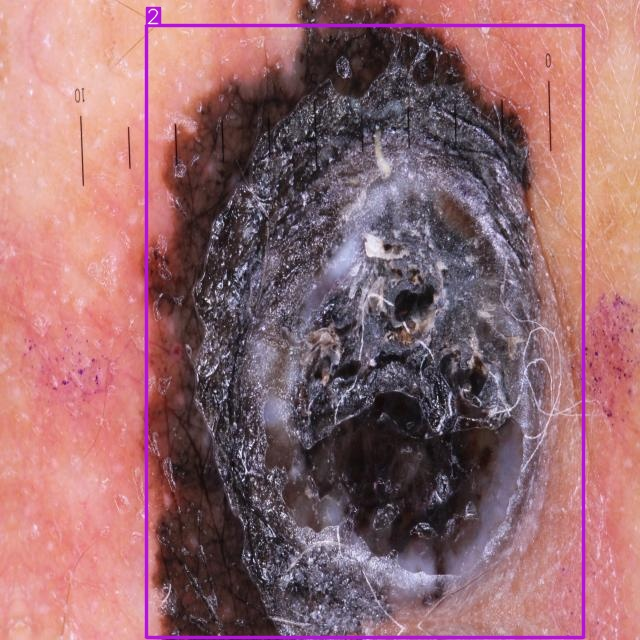

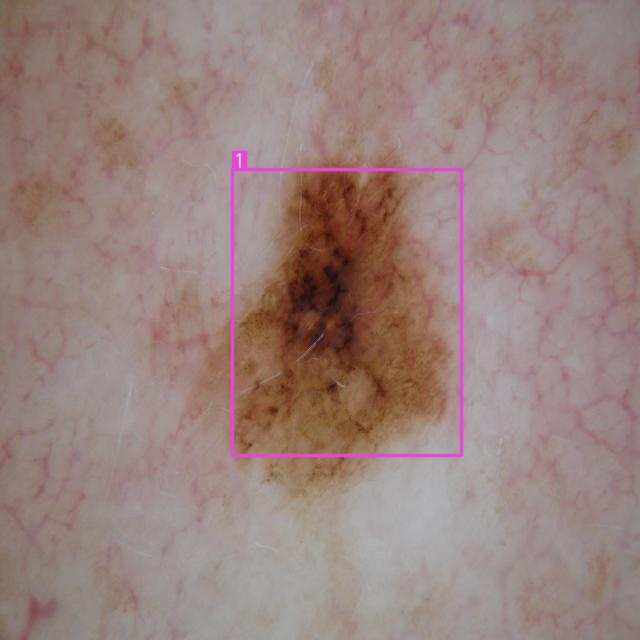

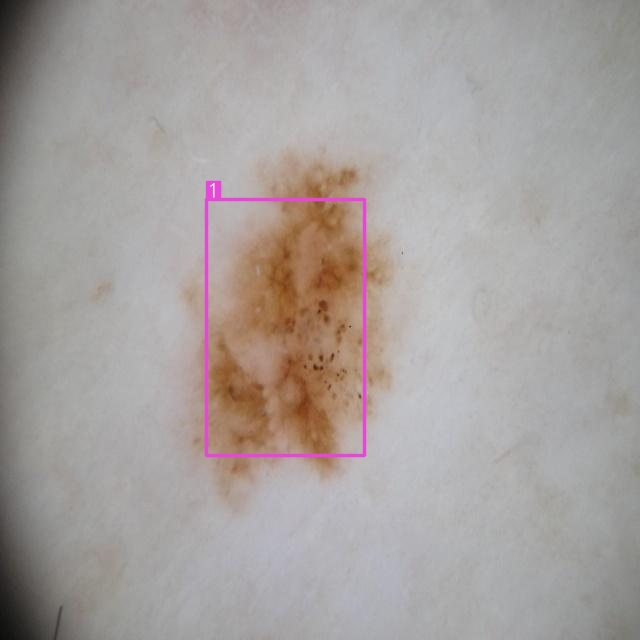

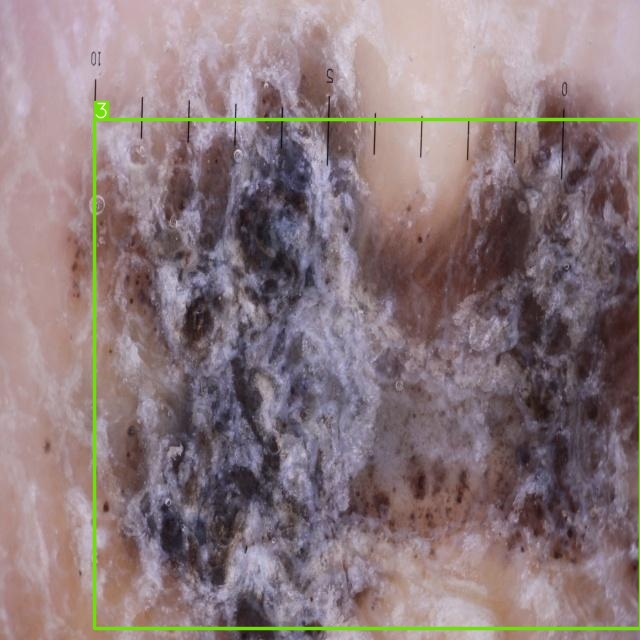

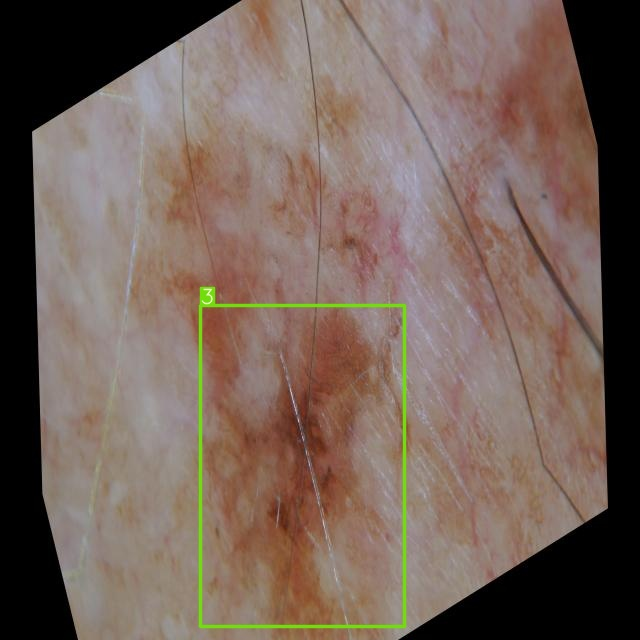

In [19]:
#display inference on ALL test images
#this looks much better with longer training above
import glob
from IPython.display import Image, display

%cd /content/ScaledYOLOv4/
for imageName in glob.glob('./inference/output/*.jpg'): #assuming JPG
    display(Image(filename=imageName))
    print("\n")

# Export Trained Weights for Future Inference

Now that you have trained your custom detector, you can export the trained weights you have made here for inference on your device elsewhere

In [22]:
from google.colab import files
files.download('./runs/exp0_yolov4-csp-results/weights/best_yolov4-csp-results.pt')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [23]:
import shutil
from google.colab import files

# Define the directory and output zip file name
directory_to_zip = '/content/ScaledYOLOv4/inference/output'
output_filename = '/content/yolov4_runs.zip'

# Zip the directory
shutil.make_archive(output_filename.replace('.zip', ''), 'zip', directory_to_zip)

# Download the zipped file
files.download(output_filename)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>